# Context reliance on COCO-MLT

Repeats the context-reliance check on **COCO-MLT** (Wu et al., ECCV
2020: 1,909 training images, 80 classes, 25 tail classes with fewer
than 20 training images; evaluated on the 5,000 COCO val2017 images).

Why COCO-MLT: its 80 classes are flat and coarse (person, skis,
dining table), so co-occurrence is mostly *scene context*, not
siblings or parents. COCO labels every class in every image, so every
absent class is a verified negative: thousands per class instead of
about six.

**What it does**
1. Downloads the COCO-MLT split (pinned to the authors' repository
   and checked by SHA-256), the COCO annotations and the 6,909 images.
2. Builds image labels exactly as the authors do, and checks them
   against the authors' own label file.
3. Encodes images with frozen CLIP ViT-B/16 (as in your pilot).
4. Trains linear heads with **BCE**, **ASL** and **DB-Focal** (the
   authors' long-tail loss and class-aware sampling), 3 seeds each,
   with each loss's learning rate and epochs chosen on held-out
   training images.
5. Runs the context-reliance check with all, context-only and
   related-only companions.

## Step 0: setup

In [1]:
import hashlib, importlib, json, os, pickle, sys, time, urllib.request, zipfile
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import Image as ShowImage, display

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")

missing = []
for module in ("torch", "clip", "PIL"):
    try:
        __import__(module)
    except ImportError:
        missing.append(module)
import torch
import torch.nn.functional as F
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}, device: {device}")
print("context_reliance_check.py: up to date")
if "clip" in missing:
    print("CLIP is not installed. Step 6 needs it: "
          "pip install git+https://github.com/openai/CLIP.git")
if "PIL" in missing:
    print("Pillow is not installed. Step 6 needs it: pip install pillow")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130, device: cuda
context_reliance_check.py: up to date


## Step 1: settings

In [2]:
DATA = "coco_mlt"            # everything is stored here
MODEL_CACHE = "model_cache"  # folder holding ViT-B-16.pt
SEEDS = [42, 43, 44]
BATCH, WEIGHT_DECAY = 64, 1e-4
# Learning rate and epochs are chosen per loss on held-out training
# images (Step 9), never on the evaluation images.
LR_GRID = [1e-3, 3e-3, 1e-2]
EPOCH_MARKS = [50, 100, 200]
RELATED_PCT = 5              # top 5% most text-similar labels = "close"
DOWNLOAD_WORKERS = 16
RETRAIN = False              # True retrains heads even if saved

SPLIT_COMMIT = "14460d0acda6a3e77a8a6a5999b9746243cb1535"
SPLIT_URL = ("https://raw.githubusercontent.com/wutong16/"
             f"DistributionBalancedLoss/{SPLIT_COMMIT}/appendix/coco/"
             "longtail2017/")
SPLIT_SHA256 = {
    "img_id.pkl": "f31e853d2c7b69512c62b65ff1db067a49b3ab86a62f685c7da86b7c3dd04768",
    "class_split.pkl": "923d001a2d117e250caf48833f7082dc090aa405a1769489bf66137c8a2c5560",
    "class_freq.pkl": "7edbc381296400727d1fd8afa01af51403de8d0e892230e16312b2ae7f6a469c",
}
ANN_URL = ("http://images.cocodataset.org/annotations/"
           "annotations_trainval2017.zip")
IMG_URL = "http://images.cocodataset.org/{split}/{file_name}"

PATHS = {name: os.path.join(DATA, name) for name in (
    "split", "annotations", "images", "features", "check_inputs",
    "preds", "results")}
for path in PATHS.values():
    os.makedirs(path, exist_ok=True)

pd.DataFrame({"setting": ["data folder", "CLIP weights folder", "seeds",
                          "batch / weight decay",
                          "learning rates tried", "epochs tried",
                          "related labels"],
              "value": [os.path.abspath(DATA),
                        os.path.abspath(MODEL_CACHE), SEEDS,
                        f"{BATCH} / {WEIGHT_DECAY}", LR_GRID, EPOCH_MARKS,
                        f"top {RELATED_PCT}% most text-similar"]})

,setting,value
0,data folder,c:\Users\Admin\pilot-20261029T110719Z-1-001\co...
1,CLIP weights folder,c:\Users\Admin\pilot-20261029T110719Z-1-001\mo...
2,seeds,"[42, 43, 44]"
3,batch / weight decay,64 / 0.0001
4,learning rates tried,"[0.001, 0.003, 0.01]"
5,epochs tried,"[50, 100, 200]"
6,related labels,top 5% most text-similar


## Step 2: helper functions

In [3]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def download(url, path, expected_sha256=None, retries=3, report=False):
    """Download url to path (skipped if already there and valid)."""
    if os.path.exists(path) and (expected_sha256 is None
                                 or sha256(path) == expected_sha256):
        return "cached"
    tmp, last = path + ".part", None
    for attempt in range(1, retries + 1):
        try:
            request = urllib.request.Request(
                url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=60) as r, \
                    open(tmp, "wb") as f:
                total = int(r.headers.get("Content-Length") or 0)
                done, next_mark = 0, 0.1
                while True:
                    chunk = r.read(1 << 20)
                    if not chunk:
                        break
                    f.write(chunk)
                    done += len(chunk)
                    if report and total and done / total >= next_mark:
                        print(f"  {os.path.basename(path)}: "
                              f"{100 * done / total:.0f}% of "
                              f"{total / 1e6:.0f} MB")
                        next_mark += 0.1
            os.replace(tmp, path)
            if expected_sha256 and sha256(path) != expected_sha256:
                os.remove(path)
                raise ValueError("checksum mismatch")
            return "downloaded"
        except Exception as error:  # retry network hiccups
            last = error
            time.sleep(2 * attempt)
    raise RuntimeError(f"Could not download {url}: {last}")


class SafeUnpickler(pickle.Unpickler):
    """Loads the split pickles while refusing anything but plain data."""
    ALLOWED = {("builtins", n) for n in ("set", "frozenset", "dict",
                                         "list", "tuple", "int",
                                         "float", "str")}
    ALLOWED |= {("numpy", "ndarray"), ("numpy", "dtype"),
                ("multiarray", "_reconstruct"), ("multiarray", "scalar"),
                ("_codecs", "encode"), ("collections", "OrderedDict")}

    def find_class(self, module, name):
        if module == "__builtin__":
            module = "builtins"
        short = module.rsplit(".", 1)[-1] if module.startswith("numpy") \
            and module != "numpy" else module
        if (short, name) not in self.ALLOWED:
            raise pickle.UnpicklingError(f"blocked: {module}.{name}")
        if short == "multiarray":
            try:
                import numpy._core.multiarray as m
            except ImportError:
                import numpy.core.multiarray as m
            return getattr(m, name)
        return super().find_class(module, name)


def safe_load(path):
    with open(path, "rb") as f:
        return SafeUnpickler(f, encoding="latin1").load()


def image_labels(coco, image_ids, cat_ids):
    """Image x class presence, using the authors' rules: every
    annotation counts except zero-area or sub-pixel boxes."""
    col = {c: j for j, c in enumerate(cat_ids)}
    row = {i: k for k, i in enumerate(image_ids)}
    Y = np.zeros((len(image_ids), len(cat_ids)), dtype=bool)
    for ann in coco["annotations"]:
        k = row.get(ann["image_id"])
        if k is None or ann.get("ignore", False):
            continue
        _, _, w, h = ann["bbox"]
        if ann["area"] <= 0 or w < 1 or h < 1:
            continue
        Y[k, col[ann["category_id"]]] = True
    return Y


print("Defined: sha256, download, SafeUnpickler, safe_load, image_labels")

Defined: sha256, download, SafeUnpickler, safe_load, image_labels


## Step 3: COCO-MLT split files (checked against pinned checksums)

In [4]:
status = {}
for name, digest in SPLIT_SHA256.items():
    status[name] = download(SPLIT_URL + name,
                            os.path.join(PATHS["split"], name), digest)

# img_id.pkl is a plain text list of image ids despite its name
with open(os.path.join(PATHS["split"], "img_id.pkl")) as f:
    train_ids = [int(line) for line in f if line.strip()]
class_split = safe_load(os.path.join(PATHS["split"], "class_split.pkl"))
class_freq = safe_load(os.path.join(PATHS["split"], "class_freq.pkl"))

print(f"{len(train_ids)} training image ids; classes per group: "
      + ", ".join(f"{k} {len(v)}" for k, v in class_split.items()))
pd.DataFrame({"file": list(status), "status": list(status.values()),
              "SHA-256 verified": ["yes"] * len(status)})

1909 training image ids; classes per group: head 22, middle 33, tail 25


,file,status,SHA-256 verified
0,img_id.pkl,downloaded,yes
1,class_split.pkl,downloaded,yes
2,class_freq.pkl,downloaded,yes


## Step 4: COCO annotations

Downloads `annotations_trainval2017.zip` (241 MB) once and extracts
the two instance files.

In [5]:
ANN = {split: os.path.join(PATHS["annotations"], f"instances_{split}.json")
       for split in ("train2017", "val2017")}
if all(os.path.exists(p) for p in ANN.values()):
    print("Annotation files already extracted.")
else:
    zip_path = os.path.join(PATHS["annotations"],
                            "annotations_trainval2017.zip")
    print("Downloading annotations:",
          download(ANN_URL, zip_path, report=True))
    with zipfile.ZipFile(zip_path) as z:
        for split, path in ANN.items():
            with z.open(f"annotations/instances_{split}.json") as src, \
                    open(path, "wb") as dst:
                dst.write(src.read())
    print("Extracted the train and val instance files.")
pd.DataFrame({"file": list(ANN.values()),
              "size (MB)": [round(os.path.getsize(p) / 1e6, 1)
                            for p in ANN.values()]})

  annotations_trainval2017.zip: 10% of 253 MB
  annotations_trainval2017.zip: 20% of 253 MB
  annotations_trainval2017.zip: 30% of 253 MB
  annotations_trainval2017.zip: 40% of 253 MB
  annotations_trainval2017.zip: 50% of 253 MB
  annotations_trainval2017.zip: 60% of 253 MB
  annotations_trainval2017.zip: 70% of 253 MB
  annotations_trainval2017.zip: 80% of 253 MB
  annotations_trainval2017.zip: 90% of 253 MB
  annotations_trainval2017.zip: 100% of 253 MB
Extracted the train and val instance files.


,file,size (MB)
0,coco_mlt\annotations\instances_train2017.json,469.8
1,coco_mlt\annotations\instances_val2017.json,20.0


## Step 5: labels, companions and inputs for the check

Builds labels exactly as the authors do and compares them with the
authors' own label file. Co-occurrence for choosing companions uses
the annotations of all 118,287 train2017 images (training split
only; no images needed).

In [6]:
t0 = time.time()
with open(ANN["train2017"]) as f:
    train_ann = json.load(f)
cat_ids = sorted(c["id"] for c in train_ann["categories"])
cat_name = {c["id"]: c["name"] for c in train_ann["categories"]}
names = [cat_name[c] for c in cat_ids]
train_files = {im["id"]: im["file_name"] for im in train_ann["images"]}

Y_train = image_labels(train_ann, train_ids, cat_ids)
authors = np.array(class_freq["gt_labels"], dtype=bool)
same = int((Y_train == authors).all(axis=1).sum())
counts_ok = np.array_equal(Y_train.sum(0),
                           np.asarray(class_freq["class_freq"]))
print(f"Labels match the authors' file for {same} of {len(train_ids)} "
      f"images; class counts match: {counts_ok}")
if same != len(train_ids) or not counts_ok:
    print("WARNING: labels differ from the authors' file; check before "
          "relying on the results.")

all_ids = sorted(train_files)
Y_all = image_labels(train_ann, all_ids, cat_ids).astype(np.int64)
C_full = Y_all.T @ Y_all
np.fill_diagonal(C_full, 0)
del train_ann, Y_all

with open(ANN["val2017"]) as f:
    val_ann = json.load(f)
val_images = sorted(val_ann["images"], key=lambda im: im["id"])
val_ids = [im["id"] for im in val_images]
val_files = {im["id"]: im["file_name"] for im in val_images}
Y_val = image_labels(val_ann, val_ids, cat_ids)
del val_ann

group_of = {}
for group, members in class_split.items():
    for j in members:
        group_of[int(j)] = {"middle": "medium"}.get(group, group)
cohort = [group_of[j] for j in range(len(names))]

IN = PATHS["check_inputs"]
sparse.save_npz(os.path.join(IN, "training_positives.npz"),
                sparse.csr_matrix(Y_train))
np.savez(os.path.join(IN, "val_positives.npz"), positives=Y_val)
np.savez(os.path.join(IN, "val_negatives.npz"), negatives=~Y_val)
sparse.save_npz(os.path.join(IN, "cooc_train2017.npz"),
                sparse.csr_matrix(C_full))
pd.DataFrame({"display_name": names, "cohort": cohort,
              "train_images": Y_train.sum(0),
              "val_positives": Y_val.sum(0)}).to_csv(
    os.path.join(IN, "labels.csv"), index=False)

print(f"Validation: {len(val_ids)} images, every absent class counts "
      f"as a verified negative. Done in {time.time() - t0:.0f} s.")
tail = [j for j in range(len(names)) if cohort[j] == "tail"]
top3 = lambda j: ", ".join(names[k] for k in np.argsort(-C_full[j])[:3])
pd.DataFrame({"tail class": [names[j] for j in tail],
              "COCO-MLT train images": Y_train[:, tail].sum(0),
              "val positives": Y_val[:, tail].sum(0),
              "top companions (train2017)": [top3(j) for j in tail]})

Labels match the authors' file for 1909 of 1909 images; class counts match: True
Validation: 5000 images, every absent class counts as a verified negative. Done in 28 s.


,tail class,COCO-MLT train images,val positives,top companions (train2017)
0,airplane,9,97,"person, truck, car"
1,train,18,157,"person, car, traffic light"
2,fire hydrant,11,86,"car, person, truck"
3,stop sign,13,69,"car, person, truck"
4,parking meter,8,37,"car, person, truck"
5,bird,19,125,"person, boat, bench"
6,horse,17,128,"person, car, truck"
7,sheep,7,65,"person, dog, cow"
8,cow,10,87,"person, car, horse"
9,elephant,8,89,"person, bench, car"


## Step 6: images

Downloads the 1,909 training and 5,000 validation images one by one
(resumable: finished files are skipped). Skipped entirely once the
CLIP features exist.

In [7]:
FEAT = {split: os.path.join(PATHS["features"], f"{split}_features.npy")
        for split in ("train", "val")}
image_dir = {"train2017": os.path.join(PATHS["images"], "train2017"),
             "val2017": os.path.join(PATHS["images"], "val2017")}
wanted = {"train2017": [train_files[i] for i in train_ids],
          "val2017": [val_files[i] for i in val_ids]}

if all(os.path.exists(p) for p in FEAT.values()):
    print("CLIP features already exist, so images are not needed.")
else:
    failed = []
    for split, files in wanted.items():
        os.makedirs(image_dir[split], exist_ok=True)
        todo = [f for f in files
                if not os.path.exists(os.path.join(image_dir[split], f))]
        print(f"{split}: {len(files) - len(todo)} already here, "
              f"downloading {len(todo)}")
        with ThreadPoolExecutor(DOWNLOAD_WORKERS) as pool:
            jobs = {pool.submit(download,
                                IMG_URL.format(split=split, file_name=f),
                                os.path.join(image_dir[split], f)): f
                    for f in todo}
            for k, job in enumerate(as_completed(jobs), 1):
                try:
                    job.result()
                except Exception as error:
                    failed.append((split, jobs[job], str(error)[:80]))
                if k % 500 == 0:
                    print(f"  {k} of {len(todo)} done")
    print(f"Failed downloads: {len(failed)}"
          + ("" if not failed else " - run this cell again to retry"))
pd.DataFrame({"split": list(wanted),
              "images needed": [len(v) for v in wanted.values()],
              "on disk": [sum(os.path.exists(os.path.join(image_dir[s], f))
                              for f in v) for s, v in wanted.items()]})

train2017: 0 already here, downloading 1909
  500 of 1909 done
  1000 of 1909 done
  1500 of 1909 done
val2017: 0 already here, downloading 5000
  500 of 5000 done
  1000 of 5000 done
  1500 of 5000 done
  2000 of 5000 done
  2500 of 5000 done
  3000 of 5000 done
  3500 of 5000 done
  4000 of 5000 done
  4500 of 5000 done
  5000 of 5000 done
Failed downloads: 0


,split,images needed,on disk
0,train2017,1909,1909
1,val2017,5000,5000


## Step 7: frozen CLIP ViT-B/16 features

Image features (L2-normalised, as in your pilot) and text embeddings
of the 80 class names ("a photo of a ..."), used to tell related
classes from context. Cached after the first run.

In [8]:
TEXT_EMB = os.path.join(PATHS["features"], "label_text_embeddings.npy")
if all(os.path.exists(p) for p in [*FEAT.values(), TEXT_EMB]):
    print("Loading cached CLIP features.")
else:
    import clip
    from PIL import Image
    model, preprocess = clip.load("ViT-B/16", device=device,
                                  download_root=MODEL_CACHE)
    model.eval()

    def load_image(path):
        with Image.open(path) as im:
            return preprocess(im.convert("RGB"))

    for split, ids, files, key in (
            ("train2017", train_ids, train_files, "train"),
            ("val2017", val_ids, val_files, "val")):
        paths = [os.path.join(image_dir[split], files[i]) for i in ids]
        absent = [p for p in paths if not os.path.exists(p)]
        if absent:
            raise SystemExit(f"{len(absent)} {split} images are missing; "
                             f"re-run Step 6 first.")
        chunks, t0 = [], time.time()
        with torch.no_grad():
            for start in range(0, len(paths), 64):
                batch = torch.stack([
                    load_image(p) for p in paths[start:start + 64]
                ]).to(device)
                f = model.encode_image(batch).float()
                chunks.append((f / f.norm(dim=-1, keepdim=True)).cpu().numpy())
        np.save(FEAT[key], np.concatenate(chunks).astype(np.float32))
        print(f"{split}: encoded {len(paths)} images in "
              f"{time.time() - t0:.0f} s")
    with torch.no_grad():
        tokens = clip.tokenize([f"a photo of a {n}" for n in names]).to(device)
        t = model.encode_text(tokens).float()
        np.save(TEXT_EMB, (t / t.norm(dim=-1, keepdim=True)).cpu().numpy())
    del model

X_train, X_val = np.load(FEAT["train"]), np.load(FEAT["val"])
assert X_train.shape[0] == len(train_ids) and X_val.shape[0] == len(val_ids)
pd.DataFrame({"features": ["train", "val", "class-name text"],
              "shape": [X_train.shape, X_val.shape,
                        np.load(TEXT_EMB).shape]})

train2017: encoded 1909 images in 47 s
val2017: encoded 5000 images in 121 s


,features,shape
0,train,"(1909, 512)"
1,val,"(5000, 512)"
2,class-name text,"(80, 512)"


## Step 8: losses

- **BCE**: binary cross-entropy, uniform sampling.
- **ASL**: asymmetric loss (Ridnik et al., 2021) with the usual
  settings: negative focusing 4, positive focusing 0, clip 0.05.
- **DB-Focal**: Distribution-Balanced loss as in the authors' code
  and COCO config: rebalancing weight (alpha 0.1, beta 10, mu 0.2),
  negative-tolerant regularisation (scale 2, bias 0.05), focal
  gamma 2 with balance 2, and class-aware sampling.

These are linear heads on frozen CLIP features, not the authors'
end-to-end ResNet-50 training, so mAP is not comparable with their
paper.

In [9]:
def bce_loss(logits, y):
    return F.binary_cross_entropy_with_logits(logits, y)


def asl_loss(logits, y, gamma_neg=4.0, gamma_pos=0.0, clip=0.05, eps=1e-8):
    p = torch.sigmoid(logits)
    p_neg = (1 - p + clip).clamp(max=1)
    log_terms = (y * torch.log(p.clamp(min=eps))
                 + (1 - y) * torch.log(p_neg.clamp(min=eps)))
    pt = p * y + p_neg * (1 - y)
    focus = torch.pow(1 - pt, gamma_pos * y + gamma_neg * (1 - y))
    return -(log_terms * focus).sum(1).mean()


class DBFocalLoss:
    def __init__(self, class_freq, n_train, alpha=0.1, beta=10.0, mu=0.2,
                 neg_scale=2.0, init_bias=0.05, gamma=2.0, balance=2.0):
        freq = torch.as_tensor(np.maximum(np.asarray(class_freq), 1),
                               dtype=torch.float32, device=device)
        self.freq_inv = 1.0 / freq
        self.bias = -torch.log(n_train / freq - 1) * init_bias / neg_scale
        self.alpha, self.beta, self.mu = alpha, beta, mu
        self.neg_scale, self.gamma, self.balance = neg_scale, gamma, balance

    def __call__(self, logits, y):
        repeat = (y * self.freq_inv).sum(1, keepdim=True)
        weight = torch.sigmoid(
            self.beta * (self.freq_inv.unsqueeze(0) / repeat - self.mu)
        ) + self.alpha
        z = logits + self.bias
        z = z * (1 - y) * self.neg_scale + z * y
        weight = weight / self.neg_scale * (1 - y) + weight * y
        pt = torch.exp(-F.binary_cross_entropy_with_logits(
            z, y, reduction="none"))
        loss = F.binary_cross_entropy_with_logits(
            z, y, weight=weight, reduction="none")
        return (self.balance * (1 - pt) ** self.gamma * loss).mean()


def class_aware_order(Y, n, rng):
    """Pick a class uniformly, then an image containing it."""
    members = [m for m in (np.flatnonzero(Y[:, c])
                           for c in range(Y.shape[1])) if m.size]
    picks = rng.integers(0, len(members), n)
    return np.array([rng.choice(members[c]) for c in picks])


def make_loss(name, Y):
    """DB-Focal needs the class counts of the images it trains on."""
    if name == "DB-Focal":
        return DBFocalLoss(Y.sum(0), len(Y))
    return {"BCE": bce_loss, "ASL": asl_loss}[name]


LOSSES = {name: make_loss(name, Y_train)
          for name in ("BCE", "ASL", "DB-Focal")}

# Self-test on a tiny batch: every loss should be finite and positive.
_z = torch.randn(4, len(names), device=device)
_y = torch.as_tensor(Y_train[:4], dtype=torch.float32, device=device)
pd.DataFrame({"loss": list(LOSSES),
              "value on a test batch": [round(float(fn(_z, _y)), 4)
                                        for fn in LOSSES.values()]})

,loss,value on a test batch
0,BCE,0.8170
1,ASL,13.6220
2,DB-Focal,0.6441


## Step 9: choose learning rate and epochs for each loss

Focal-type losses such as DB-Focal take smaller steps, so one shared
training budget would leave them under-trained and make them look
worse than they are. Each loss gets its own learning rate and number
of epochs, chosen on a held-out 20% of the *training* images by
mean AP over all classes. The evaluation images are never used for
this.

In [10]:
mu, sd = X_train.mean(0, keepdims=True), X_train.std(0, keepdims=True) + 1e-6
X_std, Xv_std = (X_train - mu) / sd, (X_val - mu) / sd
groups = {g: [j for j in range(len(names)) if cohort[j] == g]
          for g in ("head", "medium", "tail")}


def mean_ap(scores, Y, columns):
    aps = [crc.average_precision(scores[:, j], Y[:, j])
           for j in columns if Y[:, j].any()]
    return 100 * float(np.mean(aps))


def train_head(name, X, Y, lr, epochs, seed, eval_at=(), X_eval=None):
    """Linear head on frozen features. Returns the head, the final
    training loss and scores on X_eval at the epochs in eval_at."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    loss_fn = make_loss(name, Y)
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    Yt = torch.as_tensor(Y, dtype=torch.float32, device=device)
    Xe = (torch.as_tensor(X_eval, dtype=torch.float32, device=device)
          if X_eval is not None else None)
    head = torch.nn.Linear(X.shape[1], Y.shape[1]).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr,
                            weight_decay=WEIGHT_DECAY)
    scores_at, final = {}, float("nan")
    for epoch in range(1, epochs + 1):
        order = (class_aware_order(Y, len(Y), rng) if name == "DB-Focal"
                 else rng.permutation(len(Y)))
        total = 0.0
        for start in range(0, len(order), BATCH):
            b = torch.as_tensor(order[start:start + BATCH], device=device)
            loss = loss_fn(head(Xt[b]), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        final = total / len(order)
        if epoch in eval_at:
            with torch.no_grad():
                scores_at[epoch] = head(Xe).cpu().numpy()
    return head, final, scores_at


SELECTION = os.path.join(PATHS["preds"], "selection.csv")
if os.path.exists(SELECTION) and not RETRAIN:
    selection = pd.read_csv(SELECTION)
    print("Loaded the saved selection results.")
else:
    perm = np.random.default_rng(0).permutation(len(train_ids))
    cut = int(0.8 * len(perm))
    fit, held = perm[:cut], perm[cut:]
    rows = []
    for name in LOSSES:
        for lr in LR_GRID:
            _, _, at = train_head(name, X_std[fit], Y_train[fit], lr,
                                  max(EPOCH_MARKS), seed=0,
                                  eval_at=EPOCH_MARKS,
                                  X_eval=X_std[held])
            for epochs, scores in at.items():
                rows.append({"loss": name, "lr": lr, "epochs": epochs,
                             "held-out mAP": mean_ap(
                                 scores, Y_train[held],
                                 range(len(names)))})
            print(f"{name:<9} lr {lr:g}: held-out mAP at "
                  f"{EPOCH_MARKS} epochs = "
                  f"{[round(r['held-out mAP'], 2) for r in rows[-len(at):]]}")
    selection = pd.DataFrame(rows)
    selection.to_csv(SELECTION, index=False)

best = selection.loc[selection.groupby("loss", sort=False)
                     ["held-out mAP"].idxmax()]
CHOSEN = {r["loss"]: (float(r["lr"]), int(r["epochs"]))
          for _, r in best.iterrows()}
print("Chosen per loss:", {k: f"lr {v[0]:g}, {v[1]} epochs"
                           for k, v in CHOSEN.items()})
selection.pivot_table(index=["loss", "lr"], columns="epochs",
                      values="held-out mAP", sort=False).round(2)

BCE       lr 0.001: held-out mAP at [50, 100, 200] epochs = [60.04, 59.54, 62.58]
BCE       lr 0.003: held-out mAP at [50, 100, 200] epochs = [61.2, 62.12, 61.14]
BCE       lr 0.01: held-out mAP at [50, 100, 200] epochs = [61.48, 60.54, 59.47]
ASL       lr 0.001: held-out mAP at [50, 100, 200] epochs = [66.8, 64.91, 62.48]
ASL       lr 0.003: held-out mAP at [50, 100, 200] epochs = [63.1, 61.18, 59.64]
ASL       lr 0.01: held-out mAP at [50, 100, 200] epochs = [60.28, 59.5, 58.56]
DB-Focal  lr 0.001: held-out mAP at [50, 100, 200] epochs = [61.85, 62.06, 60.6]
DB-Focal  lr 0.003: held-out mAP at [50, 100, 200] epochs = [60.39, 59.66, 58.16]
DB-Focal  lr 0.01: held-out mAP at [50, 100, 200] epochs = [57.91, 57.67, 58.56]
Chosen per loss: {'BCE': 'lr 0.001, 200 epochs', 'ASL': 'lr 0.001, 50 epochs', 'DB-Focal': 'lr 0.001, 100 epochs'}


epochs            50     100    200
loss     lr                        
BCE      0.001  60.04  59.54  62.58
         0.003  61.20  62.12  61.14
         0.010  61.48  60.54  59.47
ASL      0.001  66.80  64.91  62.48
         0.003  63.10  61.18  59.64
         0.010  60.28  59.50  58.56
DB-Focal 0.001  61.85  62.06  60.60
         0.003  60.39  59.66  58.16
         0.010  57.91  57.67  58.56

## Step 10: train the final heads (3 losses x 3 seeds)

Each loss is trained on all 1,909 training images with its chosen
settings. Saved validation logits are reused on later runs unless
`RETRAIN = True`.

In [11]:
def pred_path(loss_name, seed):
    lr, epochs = CHOSEN[loss_name]
    return os.path.join(PATHS["preds"],
                        f"{loss_name}_lr{lr:g}_ep{epochs}_seed{seed}.npy")


runs = []
for loss_name in LOSSES:
    lr, epochs = CHOSEN[loss_name]
    for seed in SEEDS:
        path = pred_path(loss_name, seed)
        if os.path.exists(path) and not RETRAIN:
            scores, final_loss = np.load(path), float("nan")
        else:
            _, final_loss, at = train_head(loss_name, X_std, Y_train, lr,
                                           epochs, seed, eval_at=(epochs,),
                                           X_eval=Xv_std)
            scores = at[epochs].astype(np.float32)
            np.save(path, scores)
        runs.append({"loss": loss_name, "seed": seed,
                     "final train loss": final_loss,
                     **{f"{g} mAP": mean_ap(scores, Y_val, cols)
                        for g, cols in [("all", range(len(names))),
                                        *groups.items()]}})
        print(f"{loss_name:<9} seed {seed} (lr {lr:g}, {epochs} epochs): "
              f"tail mAP {runs[-1]['tail mAP']:.2f}, "
              f"all mAP {runs[-1]['all mAP']:.2f}")

runs = pd.DataFrame(runs)
summary = runs.groupby("loss", sort=False)[[c for c in runs if "mAP" in c]]
(summary.mean().round(2).astype(str) + " +/- "
 + summary.std().round(2).astype(str))

BCE       seed 42 (lr 0.001, 200 epochs): tail mAP 71.71, all mAP 65.47
BCE       seed 43 (lr 0.001, 200 epochs): tail mAP 71.59, all mAP 65.44
BCE       seed 44 (lr 0.001, 200 epochs): tail mAP 71.70, all mAP 65.40
ASL       seed 42 (lr 0.001, 50 epochs): tail mAP 71.57, all mAP 65.48
ASL       seed 43 (lr 0.001, 50 epochs): tail mAP 71.71, all mAP 65.75
ASL       seed 44 (lr 0.001, 50 epochs): tail mAP 71.59, all mAP 65.48
DB-Focal  seed 42 (lr 0.001, 100 epochs): tail mAP 69.43, all mAP 62.44
DB-Focal  seed 43 (lr 0.001, 100 epochs): tail mAP 69.50, all mAP 62.63
DB-Focal  seed 44 (lr 0.001, 100 epochs): tail mAP 69.64, all mAP 62.27


,all mAP,head mAP,medium mAP,tail mAP
loss,,,,
BCE,65.43 +/- 0.03,51.59 +/- 0.09,69.94 +/- 0.04,71.67 +/- 0.07
ASL,65.57 +/- 0.15,52.48 +/- 0.29,69.71 +/- 0.16,71.62 +/- 0.07
DB-Focal,62.45 +/- 0.18,48.2 +/- 0.18,66.59 +/- 0.43,69.52 +/- 0.11


## Step 11: context-reliance check

Runs the check three times: all companions (the primary analysis on
COCO, since its classes are flat), context-only companions (a
stricter check that also drops scene companions that happen to be
semantically similar, such as oven for toaster), and related-only
companions. BCE is the reference condition.

In [12]:
IN = PATHS["check_inputs"]
base_argv = [
    "--train-pos", os.path.join(IN, "training_positives.npz"),
    "--val-pos", os.path.join(IN, "val_positives.npz"),
    "--val-neg", os.path.join(IN, "val_negatives.npz"),
    "--labels", os.path.join(IN, "labels.csv"),
    "--cooc", os.path.join(IN, "cooc_train2017.npz"),
    "--label-embeddings", TEXT_EMB,
    "--related-pct", str(RELATED_PCT)]
for loss_name in LOSSES:
    base_argv += ["--pred", f"{loss_name}=" + ",".join(
        pred_path(loss_name, s) for s in SEEDS)]
MODES = ["all", "context", "related"]


def run_check(mode):
    try:
        crc.main(base_argv + ["--companions", mode, "--out",
                              os.path.join(PATHS["results"], mode)])
    except SystemExit as stop:
        if stop.code not in (0, None):
            print("Stopped:", stop.code)


run_check("all")

Context-reliance check for tail labels
Tail labels: 25 ('cohort' == 'tail')
Companions from: coco_mlt\check_inputs\cooc_train2017.npz; top 3 with at least 2 shared training images
Label-order check passed: 100.0% of pairs co-occurring in --train-pos also co-occur in --cooc (random order: about 84.5%).
Companion type: all co-occurring labels
Embedding order check skipped: too few label names share a word.
Without filtering, 14 of 75 usual companions (19%) are semantically close to their tail label (top 5% by text similarity).
Tail labels with at least one companion: 25 of 25
Out of context means: no companion verified present
Validation: 5000 images; verified positives 14631, verified negatives 385369

Sanity check: tail mAP from these predictions (should match the values you reported for the same runs)
  BCE              71.6669%  (3 file(s) averaged)
  ASL              71.6229%  (3 file(s) averaged)
  DB-Focal         69.5246%  (3 file(s) averaged)

Condition: BCE   (gaps in AUC point

In [13]:
run_check("context")

Context-reliance check for tail labels
Tail labels: 25 ('cohort' == 'tail')
Companions from: coco_mlt\check_inputs\cooc_train2017.npz; top 3 with at least 2 shared training images
Label-order check passed: 100.0% of pairs co-occurring in --train-pos also co-occur in --cooc (random order: about 84.5%).
Companion type: context only (labels in the tail label's top 5% most text-similar excluded)
Embedding order check skipped: too few label names share a word.
Without filtering, 14 of 75 usual companions (19%) are semantically close to their tail label (top 5% by text similarity).
Tail labels with at least one companion: 25 of 25
Out of context means: no companion verified present
Validation: 5000 images; verified positives 14631, verified negatives 385369

Sanity check: tail mAP from these predictions (should match the values you reported for the same runs)
  BCE              71.6669%  (3 file(s) averaged)
  ASL              71.6229%  (3 file(s) averaged)
  DB-Focal         69.5246%  (3 fi

In [14]:
run_check("related")

Context-reliance check for tail labels
Tail labels: 25 ('cohort' == 'tail')
Companions from: coco_mlt\check_inputs\cooc_train2017.npz; top 3 with at least 2 shared training images
Label-order check passed: 100.0% of pairs co-occurring in --train-pos also co-occur in --cooc (random order: about 84.5%).
Companion type: related only (labels in the tail label's top 5% most text-similar)
Embedding order check skipped: too few label names share a word.
Without filtering, 14 of 75 usual companions (19%) are semantically close to their tail label (top 5% by text similarity).
Tail labels with at least one companion: 25 of 25
Out of context means: no companion verified present
Validation: 5000 images; verified positives 14631, verified negatives 385369

Sanity check: tail mAP from these predictions (should match the values you reported for the same runs)
  BCE              71.6669%  (3 file(s) averaged)
  ASL              71.6229%  (3 file(s) averaged)
  DB-Focal         69.5246%  (3 file(s) ave

## Step 12: results by companion type

Gap in AUC points, 95% interval and labels contributing. Above zero
means the model does better when the usual companions match.

In [15]:
def estimate_text(r):
    if not np.isfinite(r["mean"]):
        return "not enough data"
    return (f"{r['mean']:+.2f} [{r['ci_low']:+.2f}, "
            f"{r['ci_high']:+.2f}] (n={int(r['n_labels'])})")


measure_names = {
    "matched_neg": "Negatives, control 1 (same no. of objects)",
    "centred_neg": "Negatives, control 2 (image-centred)",
    "matched_pos": "Positives, control 1 (same no. of objects)",
    "centred_pos": "Positives, control 2 (image-centred)",
}
rows = []
for mode in MODES:
    path = os.path.join(PATHS["results"], mode, "summary.csv")
    if not os.path.exists(path):
        continue
    sm = pd.read_csv(path)
    for cond in LOSSES:
        got = {m: sm[(sm.condition == cond) & (sm.measure == m)].iloc[0]
               .to_dict() for m in measure_names}
        row = {"companions": mode, "loss": cond}
        row.update({label: estimate_text(got[m])
                    for m, label in measure_names.items()})
        for side in ("neg", "pos"):
            row[f"Verdict, {'negatives' if side == 'neg' else 'positives'}"] = \
                crc.verdict(got[f"matched_{side}"], got[f"centred_{side}"],
                            "").split(" - ")[0]
        rows.append(row)
pd.DataFrame(rows).set_index(["companions", "loss"]).T

companions                                                           all  \
loss                                                                 BCE   
Negatives, control 1 (same no. of objects)   +0.77 [+0.50, +1.06] (n=25)   
Negatives, control 2 (image-centred)         +0.25 [+0.03, +0.48] (n=25)   
Positives, control 1 (same no. of objects)  +5.98 [+2.59, +10.77] (n=17)   
Positives, control 2 (image-centred)         -2.82 [-5.13, -0.98] (n=24)   
Verdict, negatives                                                 CLEAR   
Verdict, positives                                                 MIXED   

companions                                                                \
loss                                                                 ASL   
Negatives, control 1 (same no. of objects)   +0.56 [+0.28, +0.90] (n=25)   
Negatives, control 2 (image-centred)         +0.19 [-0.04, +0.43] (n=25)   
Positives, control 1 (same no. of objects)  +5.92 [+2.55, +11.05] (n=17)   
Positives, control 2 (image-centred)         -2.96 [-5.14, -1.11] (n=24)   
Verdict, negatives                                                 MIXED   
Verdict, positives                                                 MIXED   

companions                                                                \
loss                                                            DB-Focal   
Negatives, control 1 (same no. of objects)   +0.12 [-0.25, +0.50] (n=25)   
Negatives, control 2 (image-centred)         +0.21 [-0.04, +0.47] (n=25)   
Positives, control 1 (same no. of objects)  +6.19 [+2.14, +11.25] (n=17)   
Positives, control 2 (image-centred)         -3.10 [-5.50, -1.21] (n=24)   
Verdict, negatives                                             NOT CLEAR   
Verdict, positives                                                 MIXED   

companions                                                      context  \
loss                                                                BCE   
Negatives, control 1 (same no. of objects)  +0.66 [+0.37, +0.98] (n=25)   
Negatives, control 2 (image-centred)        +0.18 [-0.10, +0.46] (n=25)   
Positives, control 1 (same no. of objects)  +2.21 [+0.09, +4.91] (n=18)   
Positives, control 2 (image-centred)        -3.35 [-6.02, -1.14] (n=24)   
Verdict, negatives                                                MIXED   
Verdict, positives                                                MIXED   

companions                                                               \
loss                                                                ASL   
Negatives, control 1 (same no. of objects)  +0.49 [+0.11, +0.89] (n=25)   
Negatives, control 2 (image-centred)        +0.14 [-0.17, +0.42] (n=25)   
Positives, control 1 (same no. of objects)  +2.53 [+0.47, +5.20] (n=18)   
Positives, control 2 (image-centred)        -3.46 [-6.06, -1.20] (n=24)   
Verdict, negatives                                                MIXED   
Verdict, positives                                                MIXED   

companions                                                               \
loss                                                           DB-Focal   
Negatives, control 1 (same no. of objects)  +0.08 [-0.41, +0.53] (n=25)   
Negatives, control 2 (image-centred)        +0.17 [-0.14, +0.47] (n=25)   
Positives, control 1 (same no. of objects)  +3.93 [+1.79, +6.61] (n=18)   
Positives, control 2 (image-centred)        -3.46 [-6.30, -1.31] (n=24)   
Verdict, negatives                                            NOT CLEAR   
Verdict, positives                                                MIXED   

companions                                                      related  \
loss                                                                BCE   
Negatives, control 1 (same no. of objects)  +2.83 [+1.58, +4.31] (n=25)   
Negatives, control 2 (image-centred)        +2.32 [+1.10, +3.84] (n=25)   
Positives, control 1 (same no. of objects)  +1.62 [-0.69, +4.52] (n=23

## Step 13: change versus BCE

In [16]:
change_names = {
    "change_auc_pos_in": "Positives with a usual companion",
    "change_auc_pos_out": "Positives without one",
    "in_minus_out": "Difference (with minus without)",
    "change_auc_neg_in": "Negatives with a usual companion",
    "change_auc_neg_out": "Negatives without one",
    "change_ap": "Tail AP (all tail classes)",
}
for mode in ("all", "context"):
    path = os.path.join(PATHS["results"], mode, "comparison.csv")
    if not os.path.exists(path):
        print(f"No comparison for {mode}.")
        continue
    comparison = pd.read_csv(path)
    comparison["estimate"] = comparison.apply(estimate_text, axis=1)
    comparison["measure"] = comparison["measure"].map(change_names)
    print(f"Companions: {mode} (change versus BCE: points, 95% interval, "
          f"classes)")
    display(comparison.pivot(index="measure", columns="condition",
                             values="estimate")
            .reindex(list(change_names.values())))

Companions: all (change versus BCE: points, 95% interval, classes)


condition,ASL,DB-Focal
measure,,
Positives with a usual companion,"-0.28 [-0.52, -0.06] (n=24)","-0.92 [-1.59, -0.25] (n=24)"
Positives without one,"+0.34 [-0.29, +1.42] (n=24)","+0.61 [-0.41, +2.31] (n=24)"
Difference (with minus without),"-0.63 [-1.60, -0.05] (n=24)","-1.53 [-2.92, -0.40] (n=24)"
Negatives with a usual companion,"-0.15 [-0.38, +0.10] (n=25)","-0.43 [-0.94, +0.21] (n=25)"
Negatives without one,"-0.26 [-0.51, +0.01] (n=25)","-0.85 [-1.40, -0.18] (n=25)"
Tail AP (all tail classes),"-0.04 [-0.30, +0.26] (n=25)","-2.14 [-3.20, -1.17] (n=25)"


Companions: context (change versus BCE: points, 95% interval, classes)


condition,ASL,DB-Focal
measure,,
Positives with a usual companion,"-0.22 [-0.48, +0.05] (n=24)","-0.62 [-1.26, +0.08] (n=24)"
Positives without one,"+0.24 [-0.46, +1.35] (n=24)","-0.04 [-1.38, +1.84] (n=24)"
Difference (with minus without),"-0.45 [-1.51, +0.24] (n=24)","-0.58 [-2.03, +0.65] (n=24)"
Negatives with a usual companion,"-0.17 [-0.39, +0.08] (n=25)","-0.45 [-0.99, +0.21] (n=25)"
Negatives without one,"-0.24 [-0.50, +0.03] (n=25)","-0.82 [-1.37, -0.15] (n=25)"
Tail AP (all tail classes),"-0.04 [-0.30, +0.25] (n=25)","-2.14 [-3.21, -1.18] (n=25)"


## Step 14: figures

Companions: all


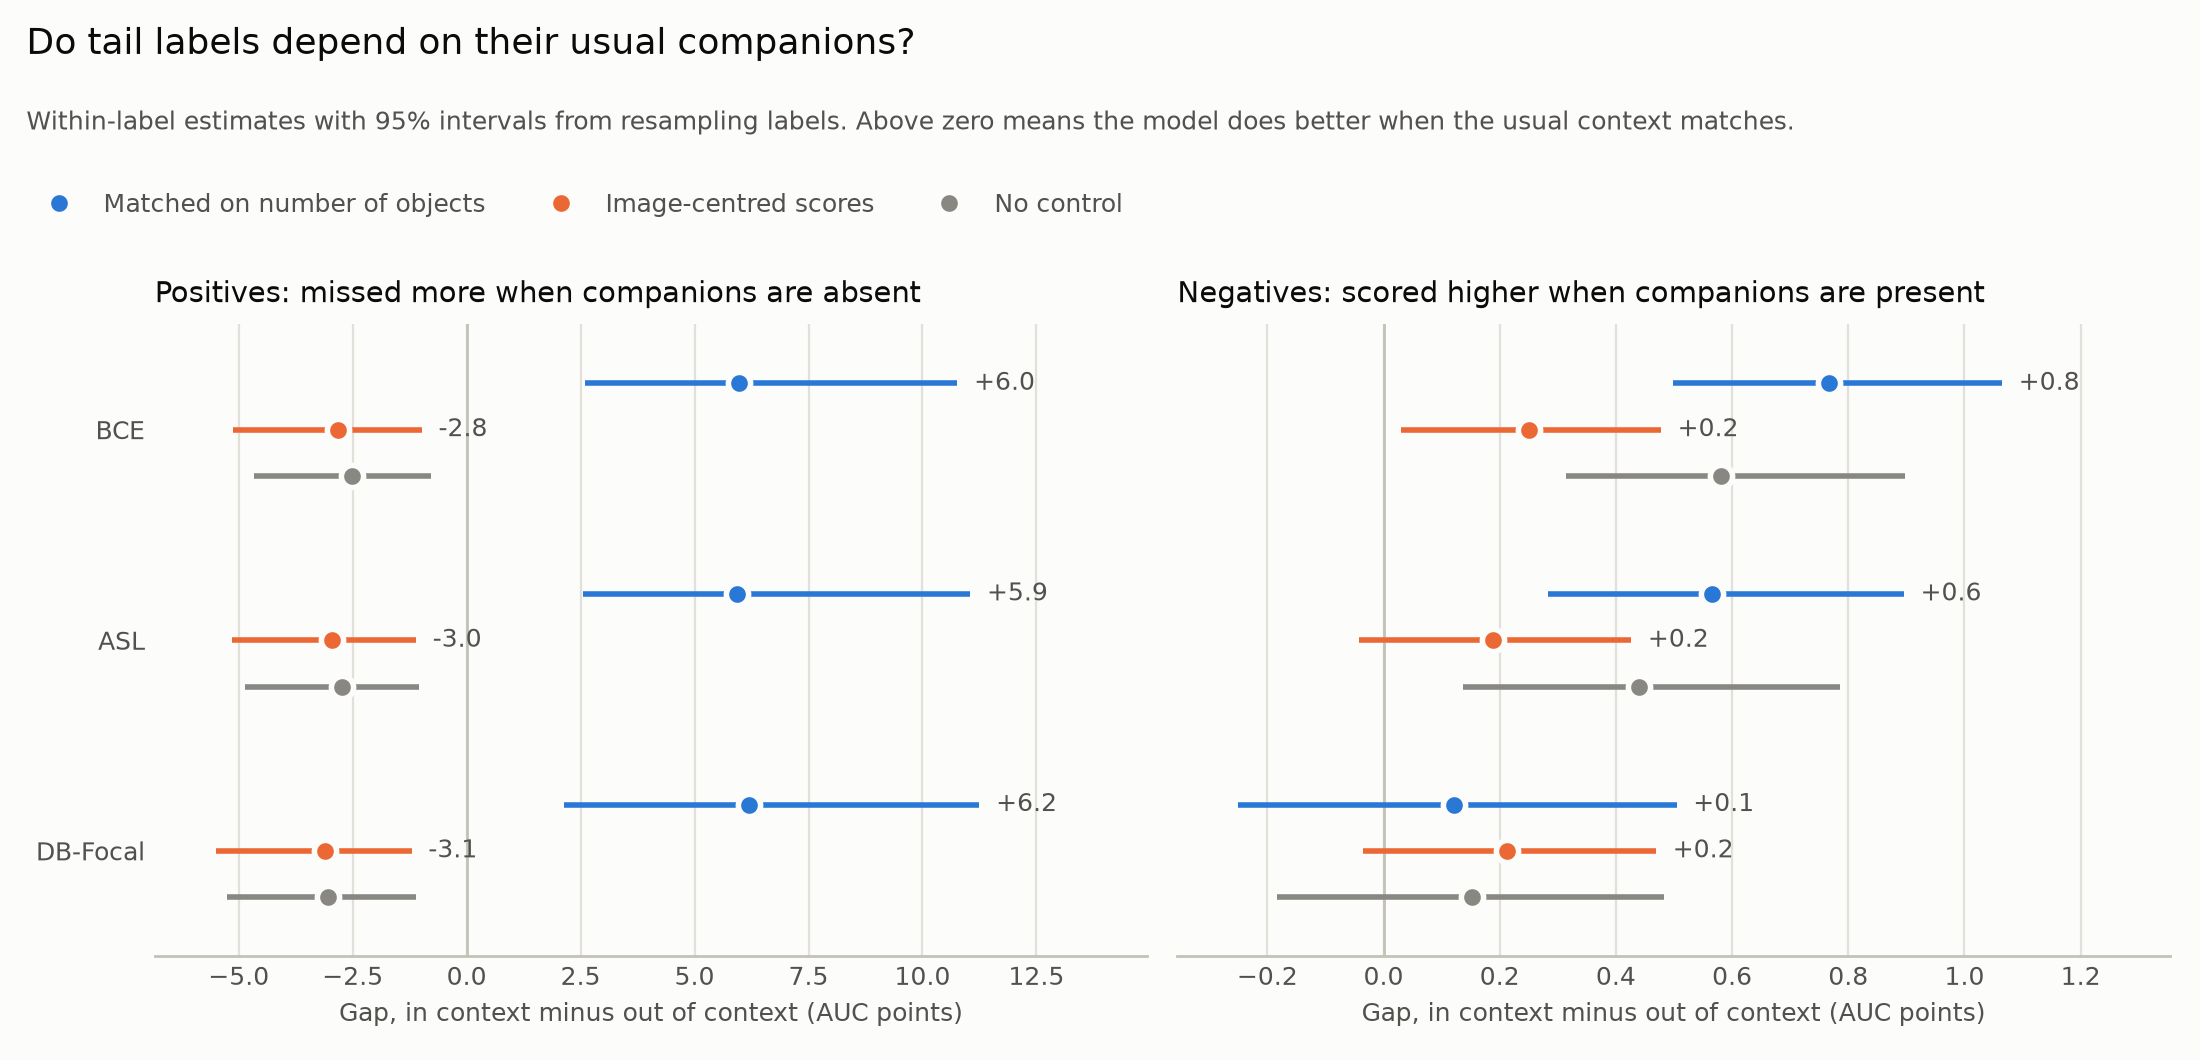

Companions: context


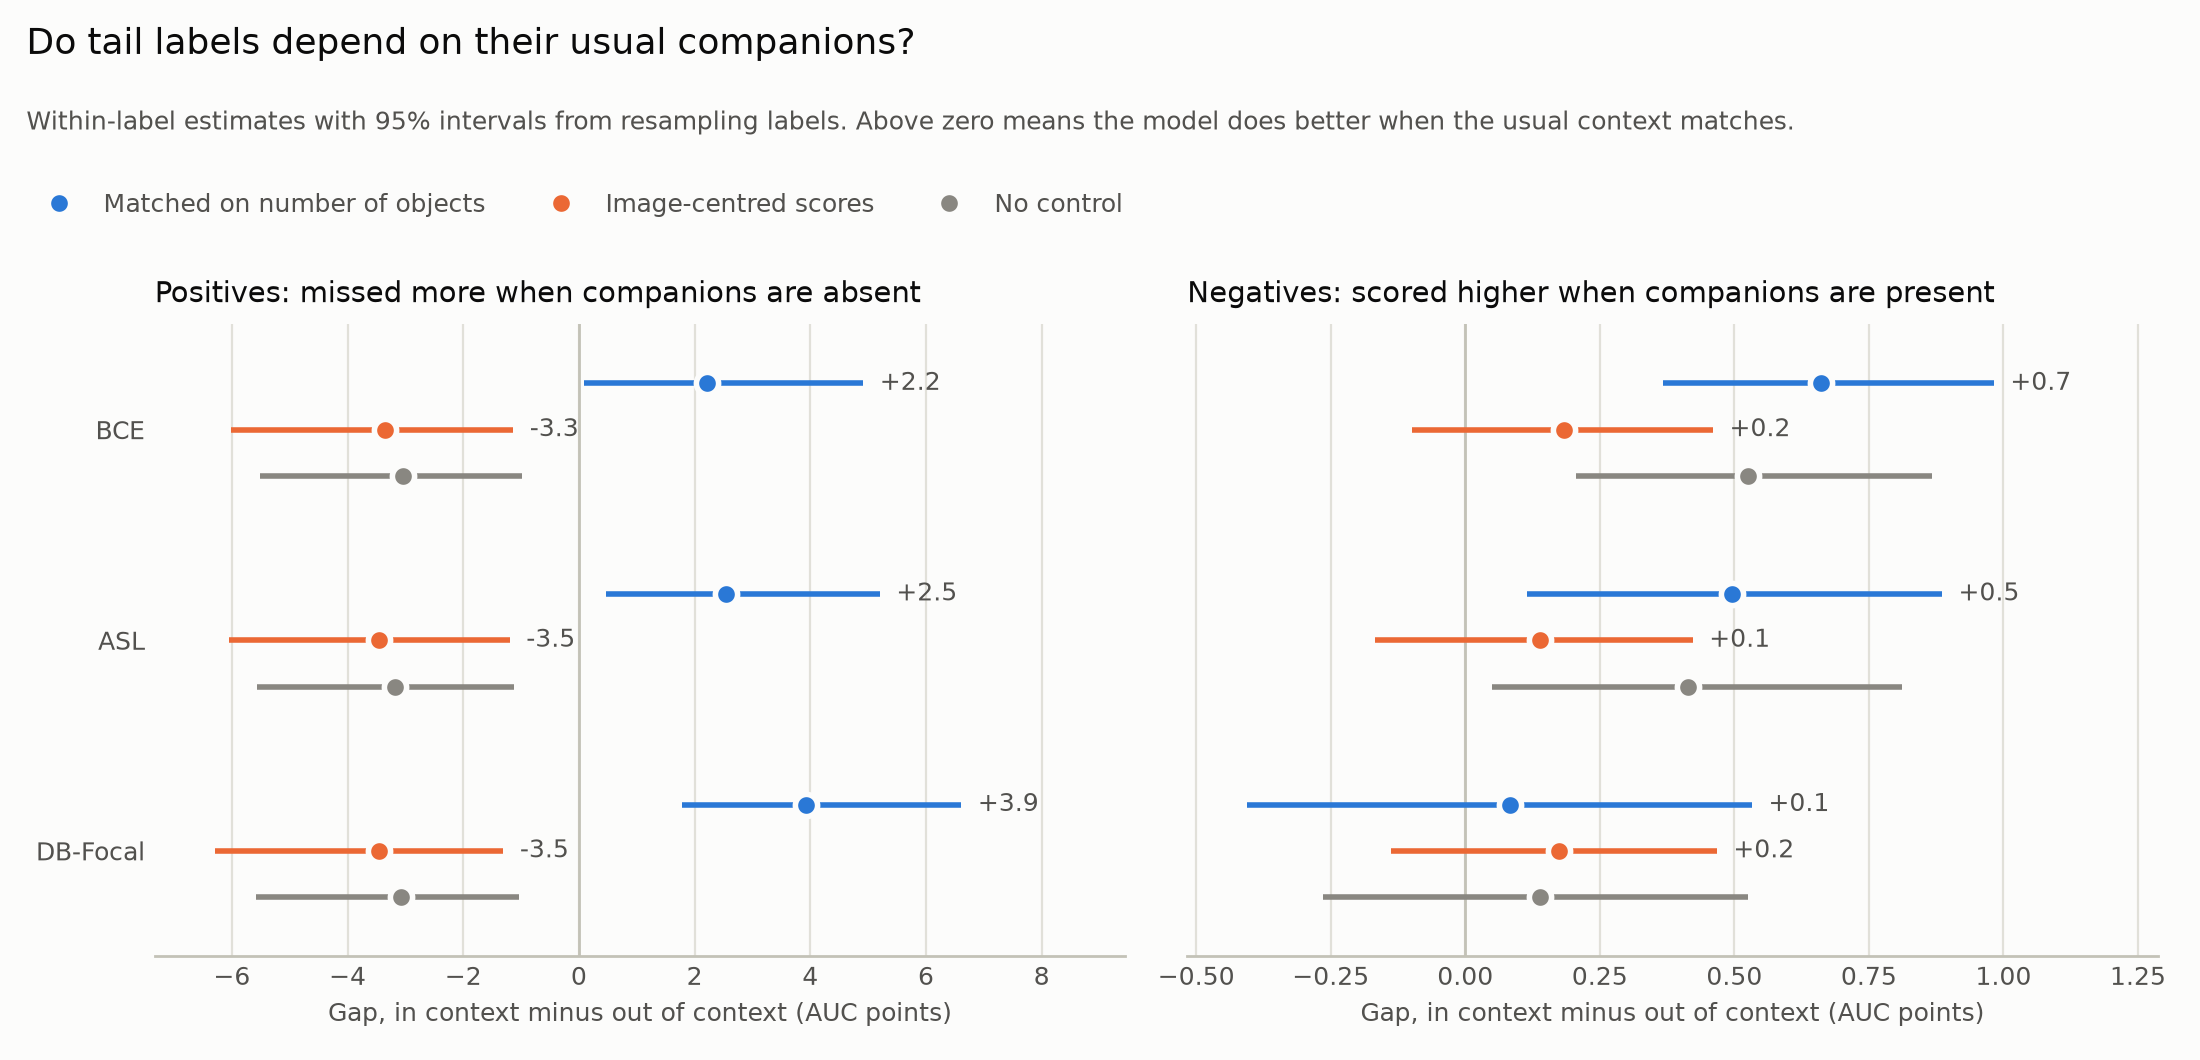

2 figure(s) shown


In [17]:
shown = 0
for mode in ("all", "context"):
    path = os.path.join(PATHS["results"], mode, "context_reliance.png")
    if os.path.exists(path):
        print(f"Companions: {mode}")
        display(ShowImage(filename=path))
        shown += 1
print(f"{shown} figure(s) shown")

## Step 15: example tail classes for slides

Tail classes with the largest negative-side gaps under BCE, with
their usual companions. With COCO's dense annotations these
per-class numbers rest on hundreds or thousands of negatives.

In [18]:
per_label = pd.read_csv(os.path.join(PATHS["results"], "all",
                                     "per_label.csv"))
cols = ["label_name", "companions", "n_neg_in", "n_neg_out",
        "auc_neg_in", "auc_neg_out", "gap_neg"]
examples = (per_label[per_label["condition"] == "BCE"]
            .dropna(subset=["gap_neg"])
            .sort_values("gap_neg", ascending=False)[cols].head(10))
print("Condition: BCE, all companions")
examples.style.format({"auc_neg_in": "{:.3f}", "auc_neg_out": "{:.3f}",
                       "gap_neg": "{:+.3f}"})

Condition: BCE, all companions


,label_name,companions,n_neg_in,n_neg_out,auc_neg_in,auc_neg_out,gap_neg
21,toaster,oven|sink|bottle,526.000000,4466.000000,0.731,0.777,+0.047
24,toothbrush,person|sink|bottle,2929.000000,2037.000000,0.930,0.951,+0.020
23,hair drier,person|sink|bottle,2954.000000,2037.000000,0.839,0.857,+0.017
15,snowboard,person|skis|backpack,2659.000000,2292.000000,0.968,0.985,+0.017
13,frisbee,person|dog|car,2877.000000,2039.000000,0.972,0.986,+0.014
2,fire hydrant,car|person|truck,2850.000000,2064.000000,0.922,0.934,+0.013
22,scissors,person|cup|bottle,2968.000000,2004.000000,0.835,0.845,+0.010
19,hot dog,person|dining table|sandwich,2925.000000,2024.000000,0.932,0.941,+0.010
20,donut,person|dining table|cup,2996.000000,1942.000000,0.940,0.946,+0.007
17,skateboard,person|car|bench,2803.000000,2070.000000,0.988,0.993,+0.006


## How to read this

- **The gap is real on COCO-MLT** if the *negatives* (or positives)
  verdict is CLEAR in the *all* rows, and ideally also in the
  *context* rows. COCO's flat classes make "all" the primary test;
  "context" is stricter because it also removes scene companions that
  are semantically similar.
- **Existing methods don't fix it** if the gap stays CLEAR under ASL
  and DB-Focal, not just BCE.
- **If DB-Focal or ASL removes it**, the gap narrows: report that
  honestly and position the method against them.
- **If nothing is CLEAR**, the Open Images signal was likely
  sibling or parent confusion rather than context reliance.
- **Check the size, not only the verdict.** With thousands of
  negatives per class, even a tiny gap can be statistically clear.
  Treat gaps under about 1 AUC point as negligible, whatever the
  verdict says. (This threshold is set before seeing the COCO
  results; for comparison, the Open Images gap was about 8 points.)